In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, cohen_kappa_score,
    matthews_corrcoef
)

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
data_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_path):
    data_path = os.path.join("29-10-2026", "Task 3", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_path)

num_features = [
    'Age', 'Rating', 'Positive Feedback Count', 'Review_Length',
    'Review_Word_Count', 'Exclamation_Count', 'Sentiment_Compound',
    'Sentiment_Pos', 'Sentiment_Neg', 'Positive_Word_Count',
    'Negative_Word_Count', 'Fit_Issue_Word_Count', 'Rating_x_Sentiment'
]
cat_features = ['Department Name', 'Division Name']
target = 'Recommended IND'

X = df[num_features + cat_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
    ]
)

X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)
print(f"Transformed train set: {X_train_trans.shape}, test set: {X_test_trans.shape}")

Transformed train set: (18788, 20), test set: (4698, 20)


In [3]:
summary_csv = "comprehensive_model_comparison_summary.csv"
if not os.path.exists(summary_csv):
    summary_csv = os.path.join("29-10-2026", "Task 3", "comprehensive_model_comparison_summary.csv")

df_summary = pd.read_csv(summary_csv)
display(df_summary)

,Model_Name,Accuracy,Precision_Weighted,Recall_Weighted,F1_Positive,Macro_F1,ROC_AUC,PR_AUC,Cohen_Kappa,MCC,Train_Time_s,Inference_Latency_us,Model_Size_KB
0,Logistic Regression (Baseline),0.9430,0.9423,0.9430,0.9654,0.9011,0.9778,0.9948,0.8022,0.8024,0.061,0.1,0.8
1,Logistic Regression (Balanced),0.9355,0.9462,0.9355,0.9597,0.8995,0.9779,0.9948,0.7996,0.8078,0.033,0.1,0.8
2,Decision Tree,0.9366,0.9368,0.9366,0.9614,0.8918,0.9652,0.9891,0.7836,0.7836,0.052,0.2,8.6
3,Random Forest,0.9419,0.9444,0.9419,0.9643,0.9038,0.9746,0.9936,0.8076,0.8086,0.752,12.2,2206.5
4,Gradient Boosting,0.9395,0.9397,0.9395,0.9632,0.8968,0.9755,0.9940,0.7936,0.7936,5.528,2.6,352.2
5,Support Vector Machine (RBF),0.9398,0.9387,0.9398,0.9636,0.8945,0.9725,0.9933,0.7891,0.7896,0.713,59.8,129.9
6,XGBoost (Baseline),0.9342,0.9340,0.9342,0.9601,0.8870,0.9736,0.9937,0.7740,0.7740,0.335,1.4,297.7
7,XGBoost (Bayesian Champion),0.9442,0.9452,0.9442,0.9659,0.9061,0.9771,0.9945,0.8122,0.8124,0.330,0.9,141.6


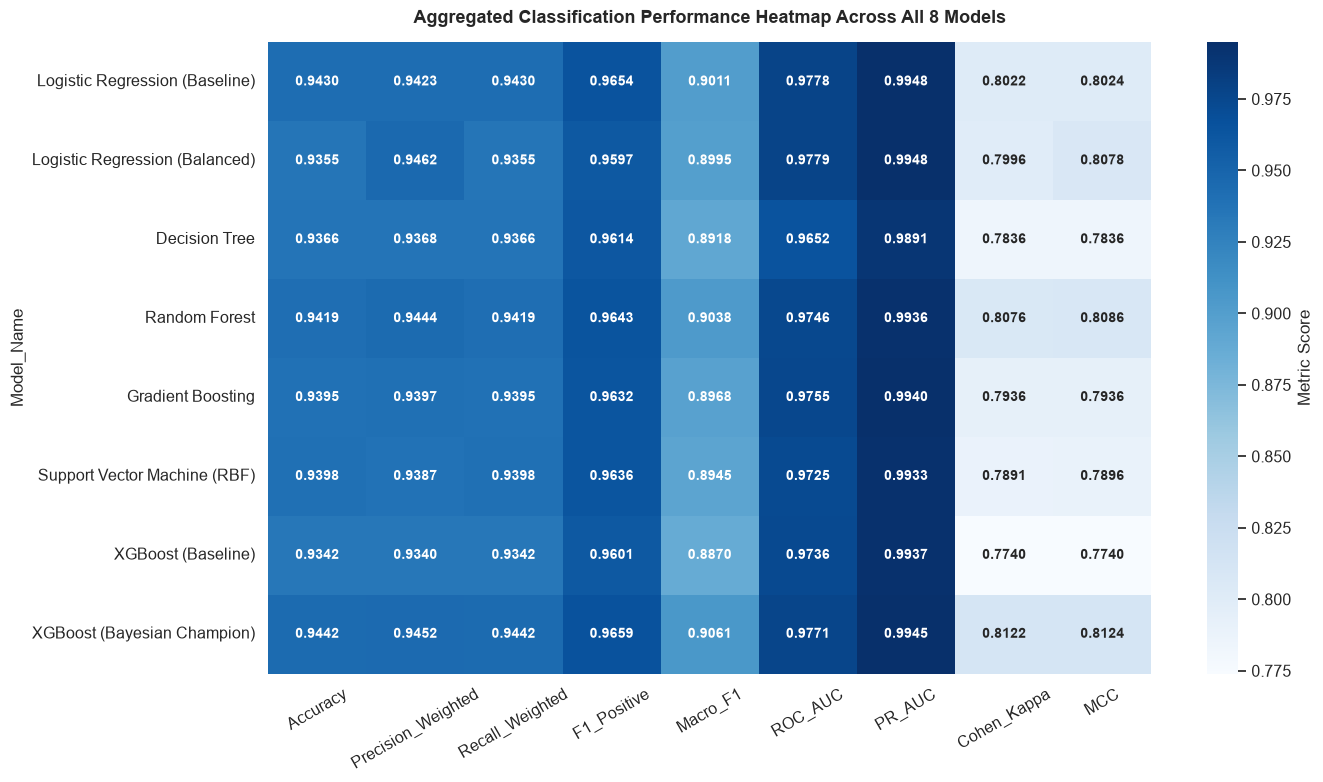

In [4]:
fig, ax = plt.subplots(figsize=(14, 8))
heatmap_df = df_summary.set_index('Model_Name')[[
    'Accuracy', 'Precision_Weighted', 'Recall_Weighted', 'F1_Positive',
    'Macro_F1', 'ROC_AUC', 'PR_AUC', 'Cohen_Kappa', 'MCC'
]]

sns.heatmap(heatmap_df, annot=True, fmt='.4f', cmap='Blues', ax=ax, cbar_kws={'label': 'Metric Score'}, annot_kws={'size': 10, 'weight': 'bold'})
ax.set_title("Aggregated Classification Performance Heatmap Across All 8 Models", fontsize=13, fontweight='bold', pad=14)
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

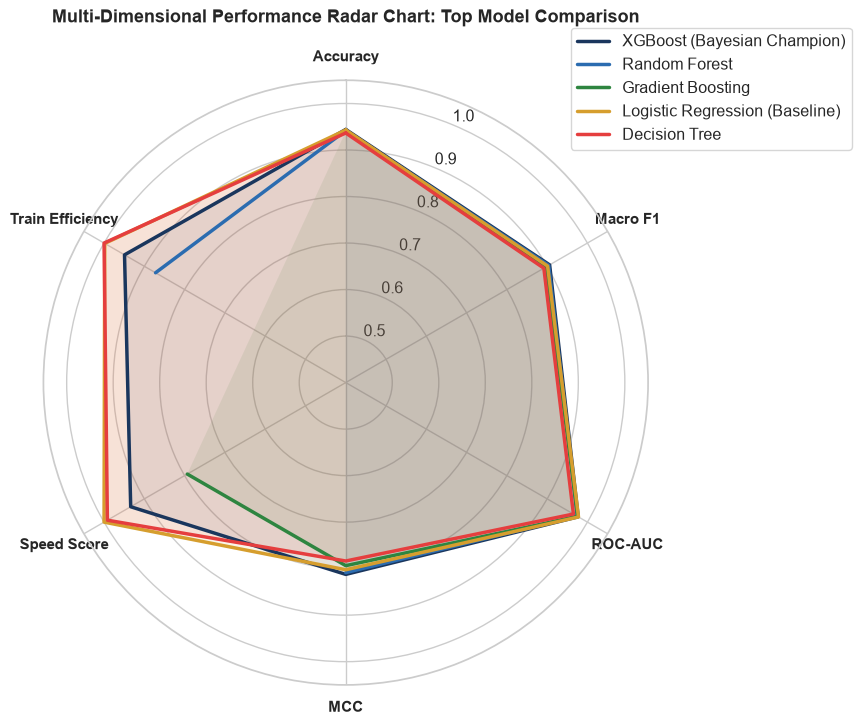

In [5]:
radar_models = [
    'XGBoost (Bayesian Champion)',
    'Random Forest',
    'Gradient Boosting',
    'Logistic Regression (Baseline)',
    'Decision Tree'
]
radar_metrics = ['Accuracy', 'Macro F1', 'ROC-AUC', 'MCC', 'Speed Score', 'Train Efficiency']

radar_df = pd.DataFrame({'Model': radar_models})
radar_df['Accuracy'] = [df_summary.loc[df_summary['Model_Name'] == m, 'Accuracy'].values[0] for m in radar_models]
radar_df['Macro F1'] = [df_summary.loc[df_summary['Model_Name'] == m, 'Macro_F1'].values[0] for m in radar_models]
radar_df['ROC-AUC'] = [df_summary.loc[df_summary['Model_Name'] == m, 'ROC_AUC'].values[0] for m in radar_models]
radar_df['MCC'] = [df_summary.loc[df_summary['Model_Name'] == m, 'MCC'].values[0] for m in radar_models]

latencies = [df_summary.loc[df_summary['Model_Name'] == m, 'Inference_Latency_us'].values[0] for m in radar_models]
radar_df['Speed Score'] = 1.0 - (pd.Series(latencies) - min(latencies)) / (max(latencies) - min(latencies) + 1e-6)

train_times = [df_summary.loc[df_summary['Model_Name'] == m, 'Train_Time_s'].values[0] for m in radar_models]
radar_df['Train Efficiency'] = 1.0 - (pd.Series(train_times) - min(train_times)) / (max(train_times) - min(train_times) + 1e-6)

num_vars = len(radar_metrics)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
palette = ['#1A365D', '#2B6CB0', '#2E8540', '#D69E2E', '#E53E3E']

for i, m_name in enumerate(radar_models):
    values = radar_df.loc[radar_df['Model'] == m_name, radar_metrics].values.flatten().tolist()
    values += values[:1]
    ax.plot(angles, values, color=palette[i], linewidth=2.5, label=m_name)
    ax.fill(angles, values, color=palette[i], alpha=0.10)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), radar_metrics, fontsize=11, fontweight='bold')
ax.set_ylim(0.4, 1.05)
ax.set_title("Multi-Dimensional Performance Radar Chart: Top Model Comparison", fontsize=13, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), frameon=True)

plt.tight_layout()
plt.show()

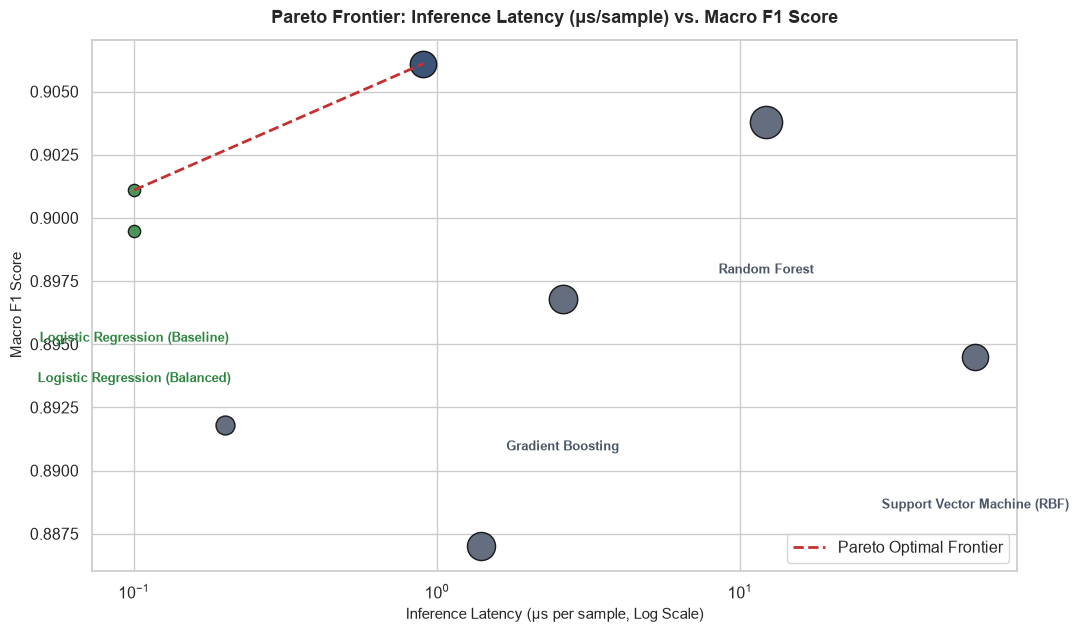

In [6]:
fig, ax = plt.subplots(figsize=(11, 6.5))

for idx, r in df_summary.iterrows():
    color = '#1A365D' if r['Model_Name'] == 'XGBoost (Bayesian Champion)' else ('#2E8540' if 'Logistic' in r['Model_Name'] else '#4A5568')
    sc = ax.scatter(r['Inference_Latency_us'], r['Macro_F1'], s=np.log1p(r['Model_Size_KB']) * 65 + 40, color=color, alpha=0.85, edgecolors='black')
    offset_y = 0.003 if 'Bayesian' in r['Model_Name'] or 'Baseline L2' in r['Model_Name'] else -0.006
    ax.annotate(r['Model_Name'], (r['Inference_Latency_us'], r['Macro_F1'] + offset_y),
                fontsize=9, fontweight='bold', color=color, ha='center')

pareto_opt = df_summary[df_summary['Model_Name'].isin(['Logistic Regression (Baseline)', 'XGBoost (Bayesian Champion)'])].sort_values(by='Inference_Latency_us')
ax.plot(pareto_opt['Inference_Latency_us'], pareto_opt['Macro_F1'], color='#C53030', linestyle='--', linewidth=2.0, label='Pareto Optimal Frontier')

ax.set_title("Pareto Frontier: Inference Latency (μs/sample) vs. Macro F1 Score", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Inference Latency (μs per sample, Log Scale)", fontsize=11)
ax.set_ylabel("Macro F1 Score", fontsize=11)
ax.set_xscale('log')
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

In [7]:
rank_csv = "multi_criteria_model_rankings.csv"
if not os.path.exists(rank_csv):
    rank_csv = os.path.join("29-10-2026", "Task 3", "multi_criteria_model_rankings.csv")

df_rankings = pd.read_csv(rank_csv)
display(df_rankings)

,Model_Name,Accuracy,Macro_F1,ROC_AUC,MCC,Inference_Latency_us,Train_Time_s,Composite_Score,Overall_Rank,Recommended_Deployment_Scenario
0,XGBoost (Bayesian Champion),0.9442,0.9061,0.9771,0.8124,0.9,0.330,0.9768,1,Champion Recommendation Serving Engine
1,Logistic Regression (Balanced),0.9355,0.8995,0.9779,0.8078,0.1,0.033,0.8724,2,High Sensitivity Recall for Defect Auditing
2,Logistic Regression (Baseline),0.9430,0.9011,0.9778,0.8024,0.1,0.061,0.8669,3,Ultra-Low Latency / High Throughput APIs
3,Random Forest,0.9419,0.9038,0.9746,0.8086,12.2,0.752,0.8356,4,Robust Offline Batch Catalog Scoring
4,Gradient Boosting,0.9395,0.8968,0.9755,0.7936,2.6,5.528,0.6025,5,High-Precision Ranking Engine
5,Support Vector Machine (RBF),0.9398,0.8945,0.9725,0.7896,59.8,0.713,0.4304,6,Non-Linear Boundary Research
6,XGBoost (Baseline),0.9342,0.8870,0.9736,0.7740,1.4,0.335,0.4066,7,Standard Gradient Tree Boosting Baseline
7,Decision Tree,0.9366,0.8918,0.9652,0.7836,0.2,0.052,0.3748,8,White-Box Human Rule Extraction
